In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import matplotlib as mpl
mpl.rcParams['mathtext.default'] = 'regular'
import scipy.stats
import sys,os
bme_dir = '/projects/lindorff_group/people/thd711/HDX_project/code/BME/'
sys.path.append(bme_dir)
import BME as BME

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames( path_to_dir, suffix=".xtc" ):
    filenames = os.listdir(path_to_dir)
    return [ filename for filename in filenames if filename.endswith( suffix ) ]




/tmp/ipykernel_1997749/2352187854.py:6: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  amides = np.loadtxt(f'../../MD_DATA/{protein}/{model}/amideresidues.txt', dtype=int)
/tmp/ipykernel_1997749/2352187854.py:7: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating po

76 28 (400020, 76) (400020,) (28,)


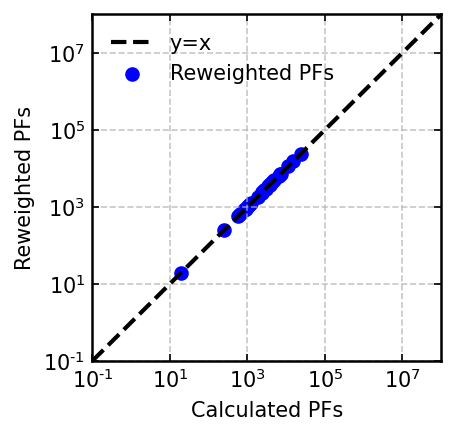

In [8]:
# checking that the calculated protection factors during reweighting are consistent

protein = 'ACP'
model = 'rewM12DH_scaled'

amides = np.loadtxt(f'../../MD_DATA/{protein}/{model}/amideresidues.txt', dtype=int)
exp_res = np.loadtxt(f'../../MD_DATA/{protein}/{model}/exp_residues.txt', dtype=int)
O = np.load(f'../../MD_DATA/{protein}/{model}/O.npy')
exp_idxs = np.array([np.where(amides == res)[0][0] for res in exp_res])
exp_data = pd.read_csv(f'../../EXP_DATA/PF_Nguyen_2018/{protein}.csv')
wopt = np.load(f'../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy')
rew_lnPF = np.loadtxt(f'../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt')

print(len(amides), len(exp_res), O.shape, wopt.shape, exp_idxs.shape)

PF = 1/np.average(O, axis=0, weights=wopt)
PF = PF[exp_idxs]

plt.figure(figsize = (3,3))
plt.scatter(PF, np.exp(rew_lnPF), color='blue', label='Reweighted PFs')
plt.plot([1e-1, 1e8], [1e-1, 1e8], color='black', linestyle='--', label='y=x')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Calculated PFs')
plt.ylabel('Reweighted PFs')
plt.xlim(1e-1, 1e8)
plt.ylim(1e-1, 1e8)
plt.legend()
plt.show()

In [9]:
np.exp(rew_lnPF)

array([1.84395855e+03, 6.36046391e+03, 2.40092922e+04, 3.70174670e+03,
       9.88824049e+02, 8.24298722e+02, 3.66942741e+03, 4.04727054e+03,
       2.68345631e+03, 1.93694093e+01, 2.38950620e+03, 5.84160102e+02,
       8.65430517e+02, 4.96314300e+03, 6.55077843e+02, 2.44611862e+02,
       1.10995563e+03, 4.60896667e+03, 7.05508293e+03, 7.22218652e+03,
       8.95173930e+02, 2.32374936e+03, 1.10462317e+03, 1.22192077e+03,
       3.46295155e+03, 2.93665074e+03, 1.50558321e+04, 1.12440111e+04])

In [10]:
PF

array([1.84395855e+03, 6.36046391e+03, 2.40092922e+04, 3.70174670e+03,
       9.88824049e+02, 8.24298722e+02, 3.66942741e+03, 4.04727054e+03,
       2.68345631e+03, 1.93694093e+01, 2.38950620e+03, 5.84160102e+02,
       8.65430517e+02, 4.96314300e+03, 6.55077843e+02, 2.44611862e+02,
       1.10995563e+03, 4.60896667e+03, 7.05508293e+03, 7.22218652e+03,
       8.95173930e+02, 2.32374936e+03, 1.10462317e+03, 1.22192077e+03,
       3.46295155e+03, 2.93665074e+03, 1.50558321e+04, 1.12440111e+04])

In [7]:
# they are identical

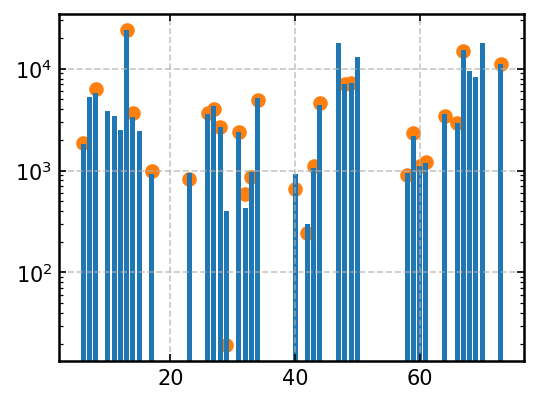

In [11]:
plt.figure(figsize=(4,3))
plt.bar(exp_data['Model_residue'], exp_data['PF'])
plt.scatter(amides[exp_idxs], PF)
plt.yscale('log')
plt.show()

In [61]:
### COMPARISON OF SOFTMAX AND LOG_LAMBDA REWEIGHTING ON THE IDPS ###

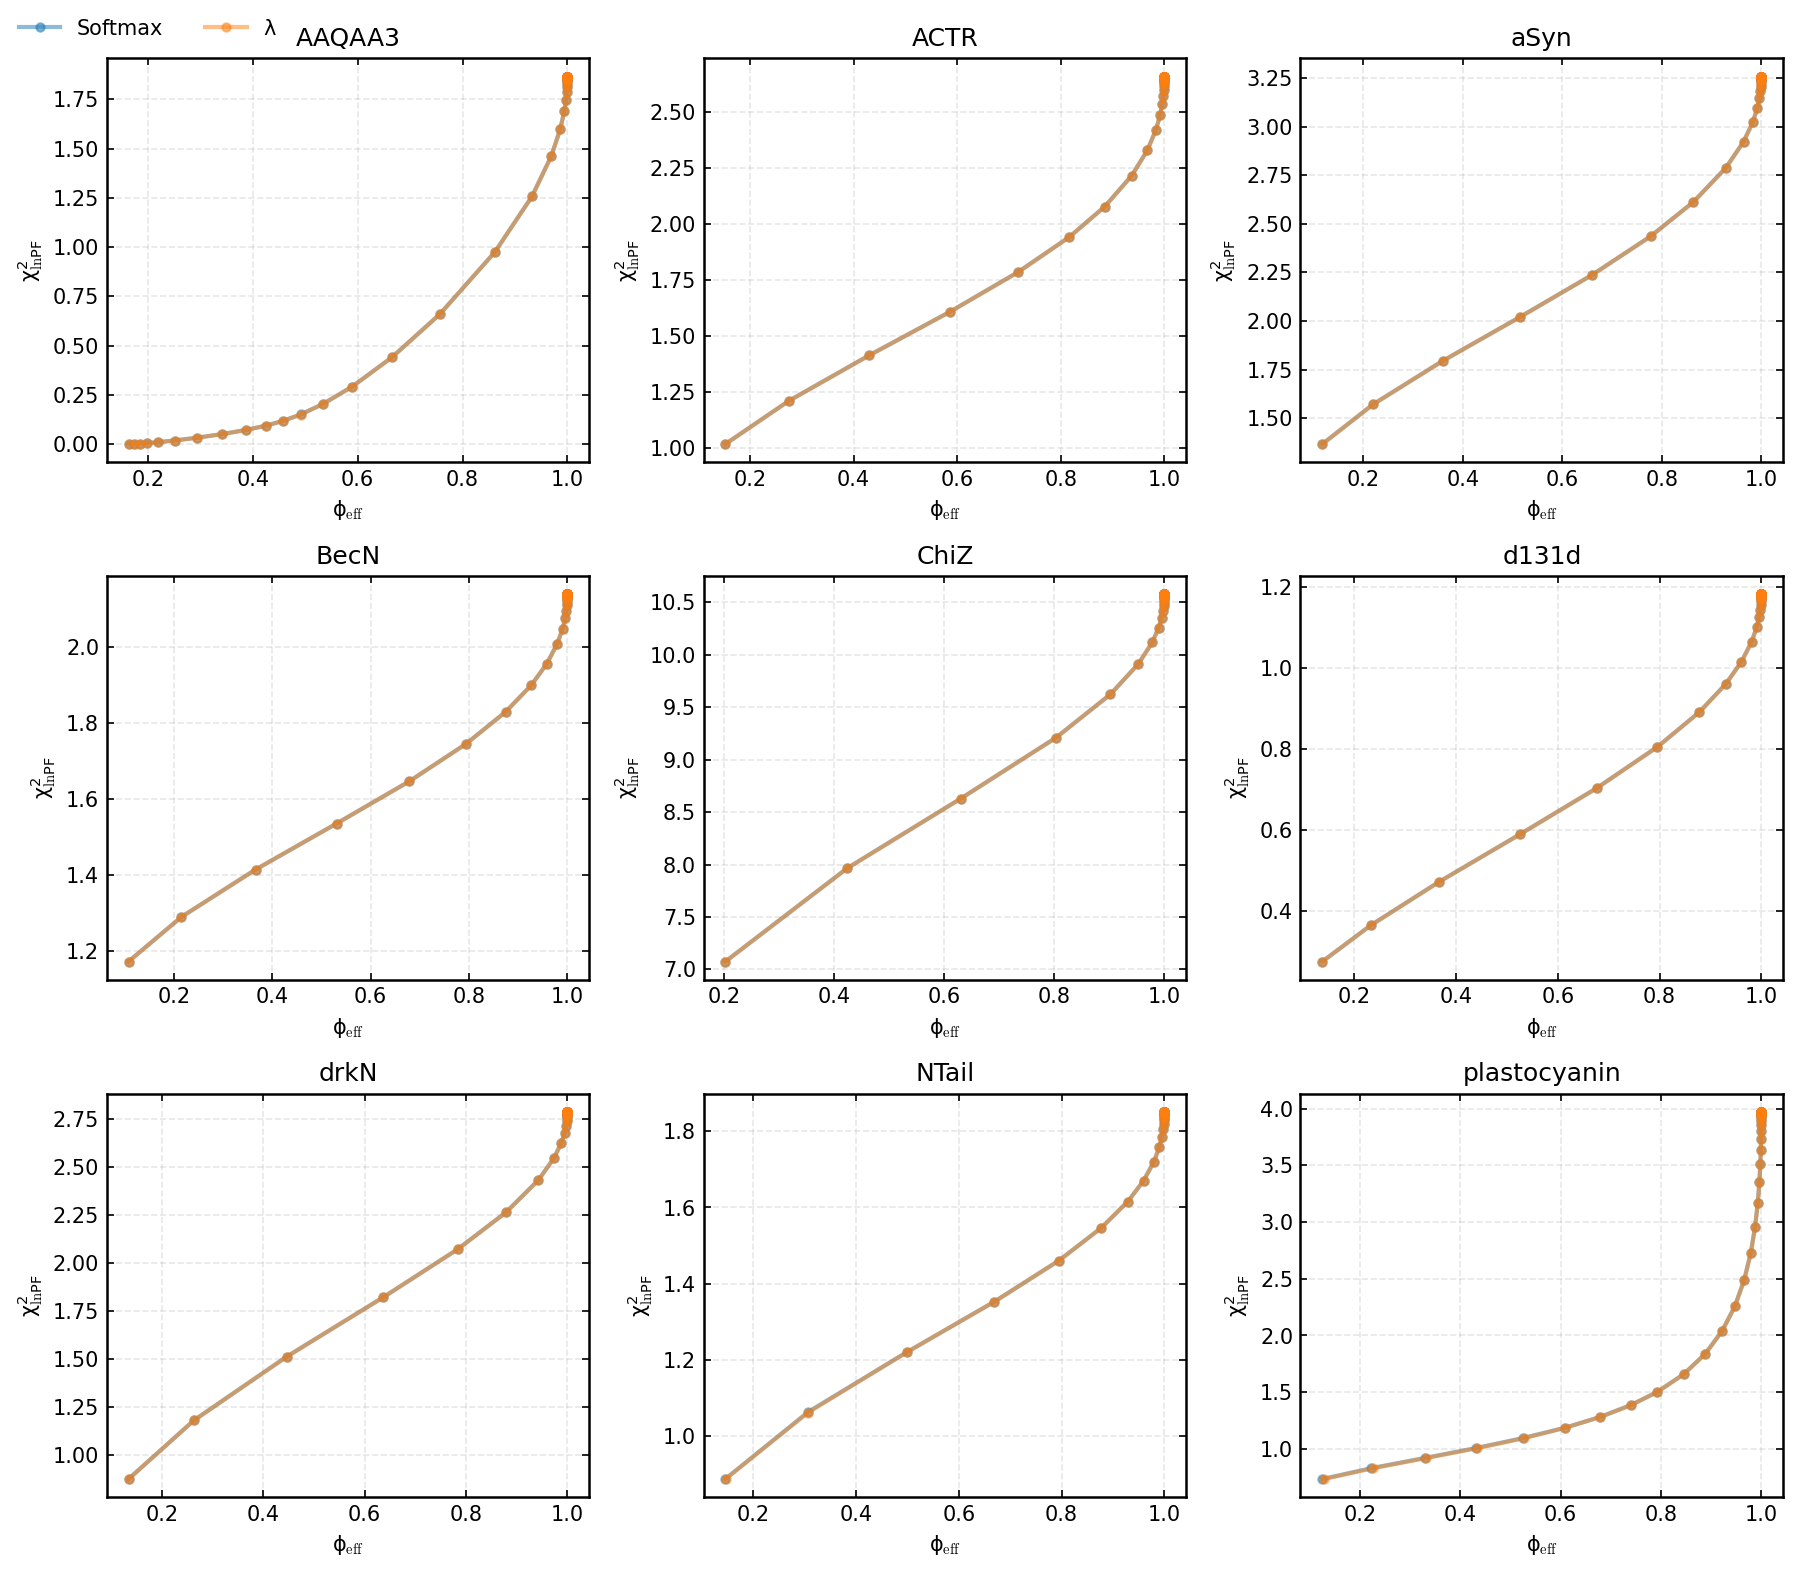

In [ ]:

# IDPs 
model = 'rewM12DH_scaled'
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail', 'plastocyanin']

ncols = 3
nrows = math.ceil(len(proteins) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.5 * nrows))
axes = np.asarray(axes).ravel()

for ax, protein in zip(axes, proteins):
    path = f'../../MD_DATA/{protein}/{model}'
    rew_data = np.loadtxt(f'{path}/log_reweighting_chi2_phi_theta.txt')
    rew_data_lambda = np.loadtxt(f'{path}/log_lambda_reweighting_chi2_phi_theta.txt')
    ax.plot(rew_data[1, :], rew_data[0, :], '-o', markersize=4, label='Softmax', alpha=0.5)
    ax.plot(rew_data_lambda[1, :], rew_data_lambda[0, :], '-o', markersize=4, label=r'$\lambda$', alpha=0.5)
    ax.set_title(protein)
    ax.set_xlabel(r'$\phi_{\mathrm{eff}}$')
    ax.set_ylabel(r'$\chi^2_{\ln PF}$')
    ax.grid(alpha=0.3)

for ax in axes[len(proteins):]:
    ax.remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=2, frameon=False)
fig.tight_layout()
plt.savefig(f'{model}_chi2_phi_multipanel.png', dpi=300, bbox_inches='tight')
plt.show()

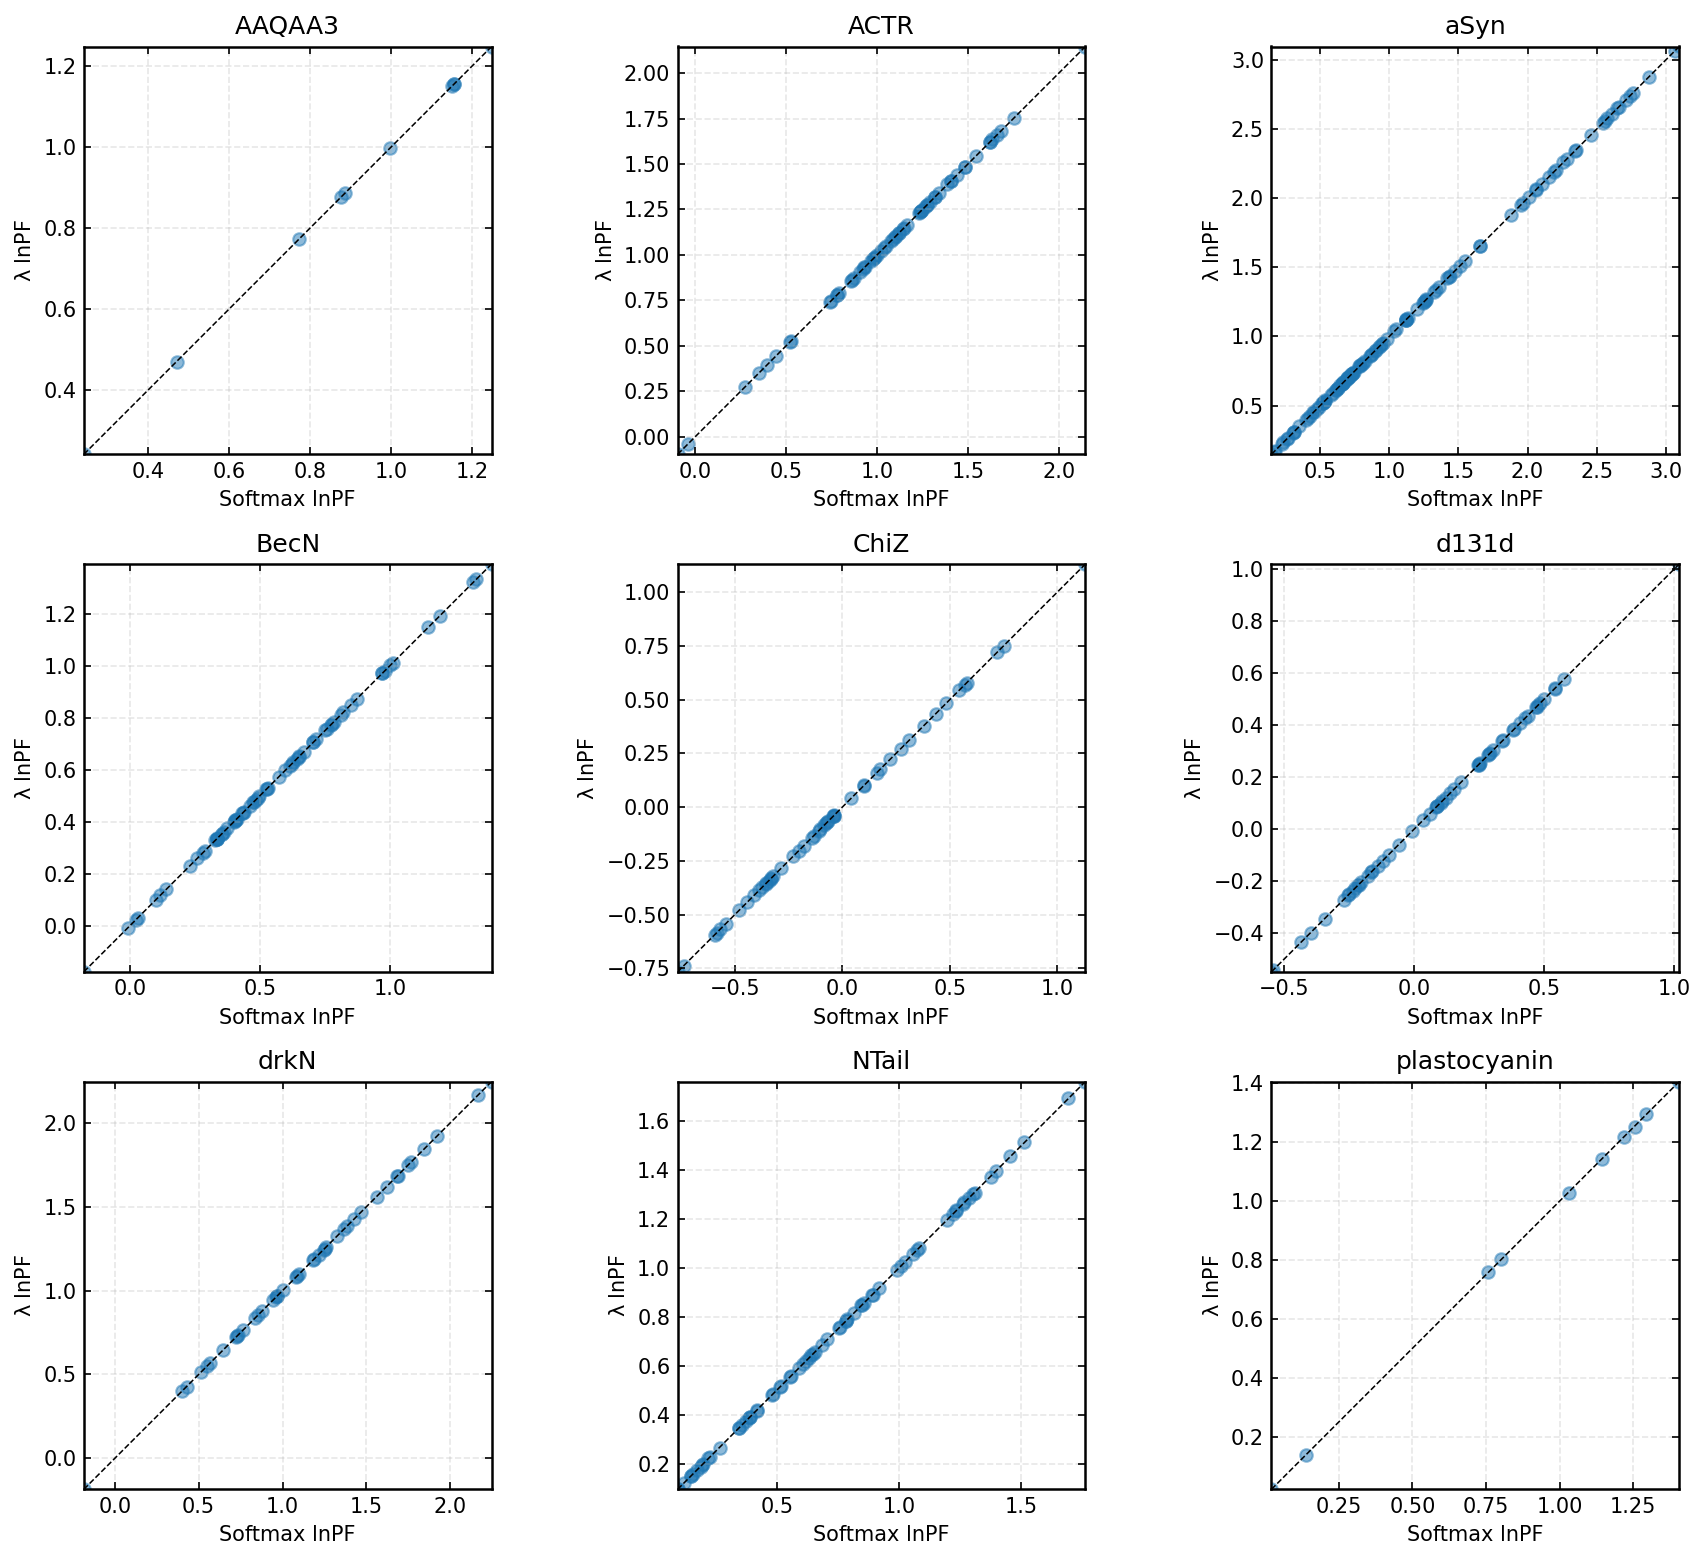

In [30]:
model = 'rewM12DH_scaled'
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail', 'plastocyanin']

ncols = 3
nrows = math.ceil(len(proteins) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.5 * nrows))
axes = np.asarray(axes).ravel()

for ax, protein in zip(axes, proteins):
    path = f'../../MD_DATA/{protein}/{model}'
    PF = np.loadtxt(f'{path}/log_rew_lnPF.txt')
    PF_lambda = np.loadtxt(f'{path}/log_lambda_rew_lnPF.txt')
    finite = np.isfinite(PF) & np.isfinite(PF_lambda)
    PF = PF[finite]
    PF_lambda = PF_lambda[finite]
    lim_min = min(PF.min(), PF_lambda.min())
    lim_max = max(PF.max(), PF_lambda.max())
    ax.scatter(PF, PF_lambda, alpha=0.5)
    ax.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', lw=0.75)
    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(lim_min, lim_max)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(protein)
    ax.set_xlabel('Softmax lnPF')
    ax.set_ylabel(r'$\lambda$ lnPF')
    ax.grid(alpha=0.3)

for ax in axes[len(proteins):]:
    ax.remove()

fig.tight_layout()
plt.savefig(f'{model}_softmax_vs_lambda_lnPF_multipanel.png', dpi=300, bbox_inches='tight')
plt.show()

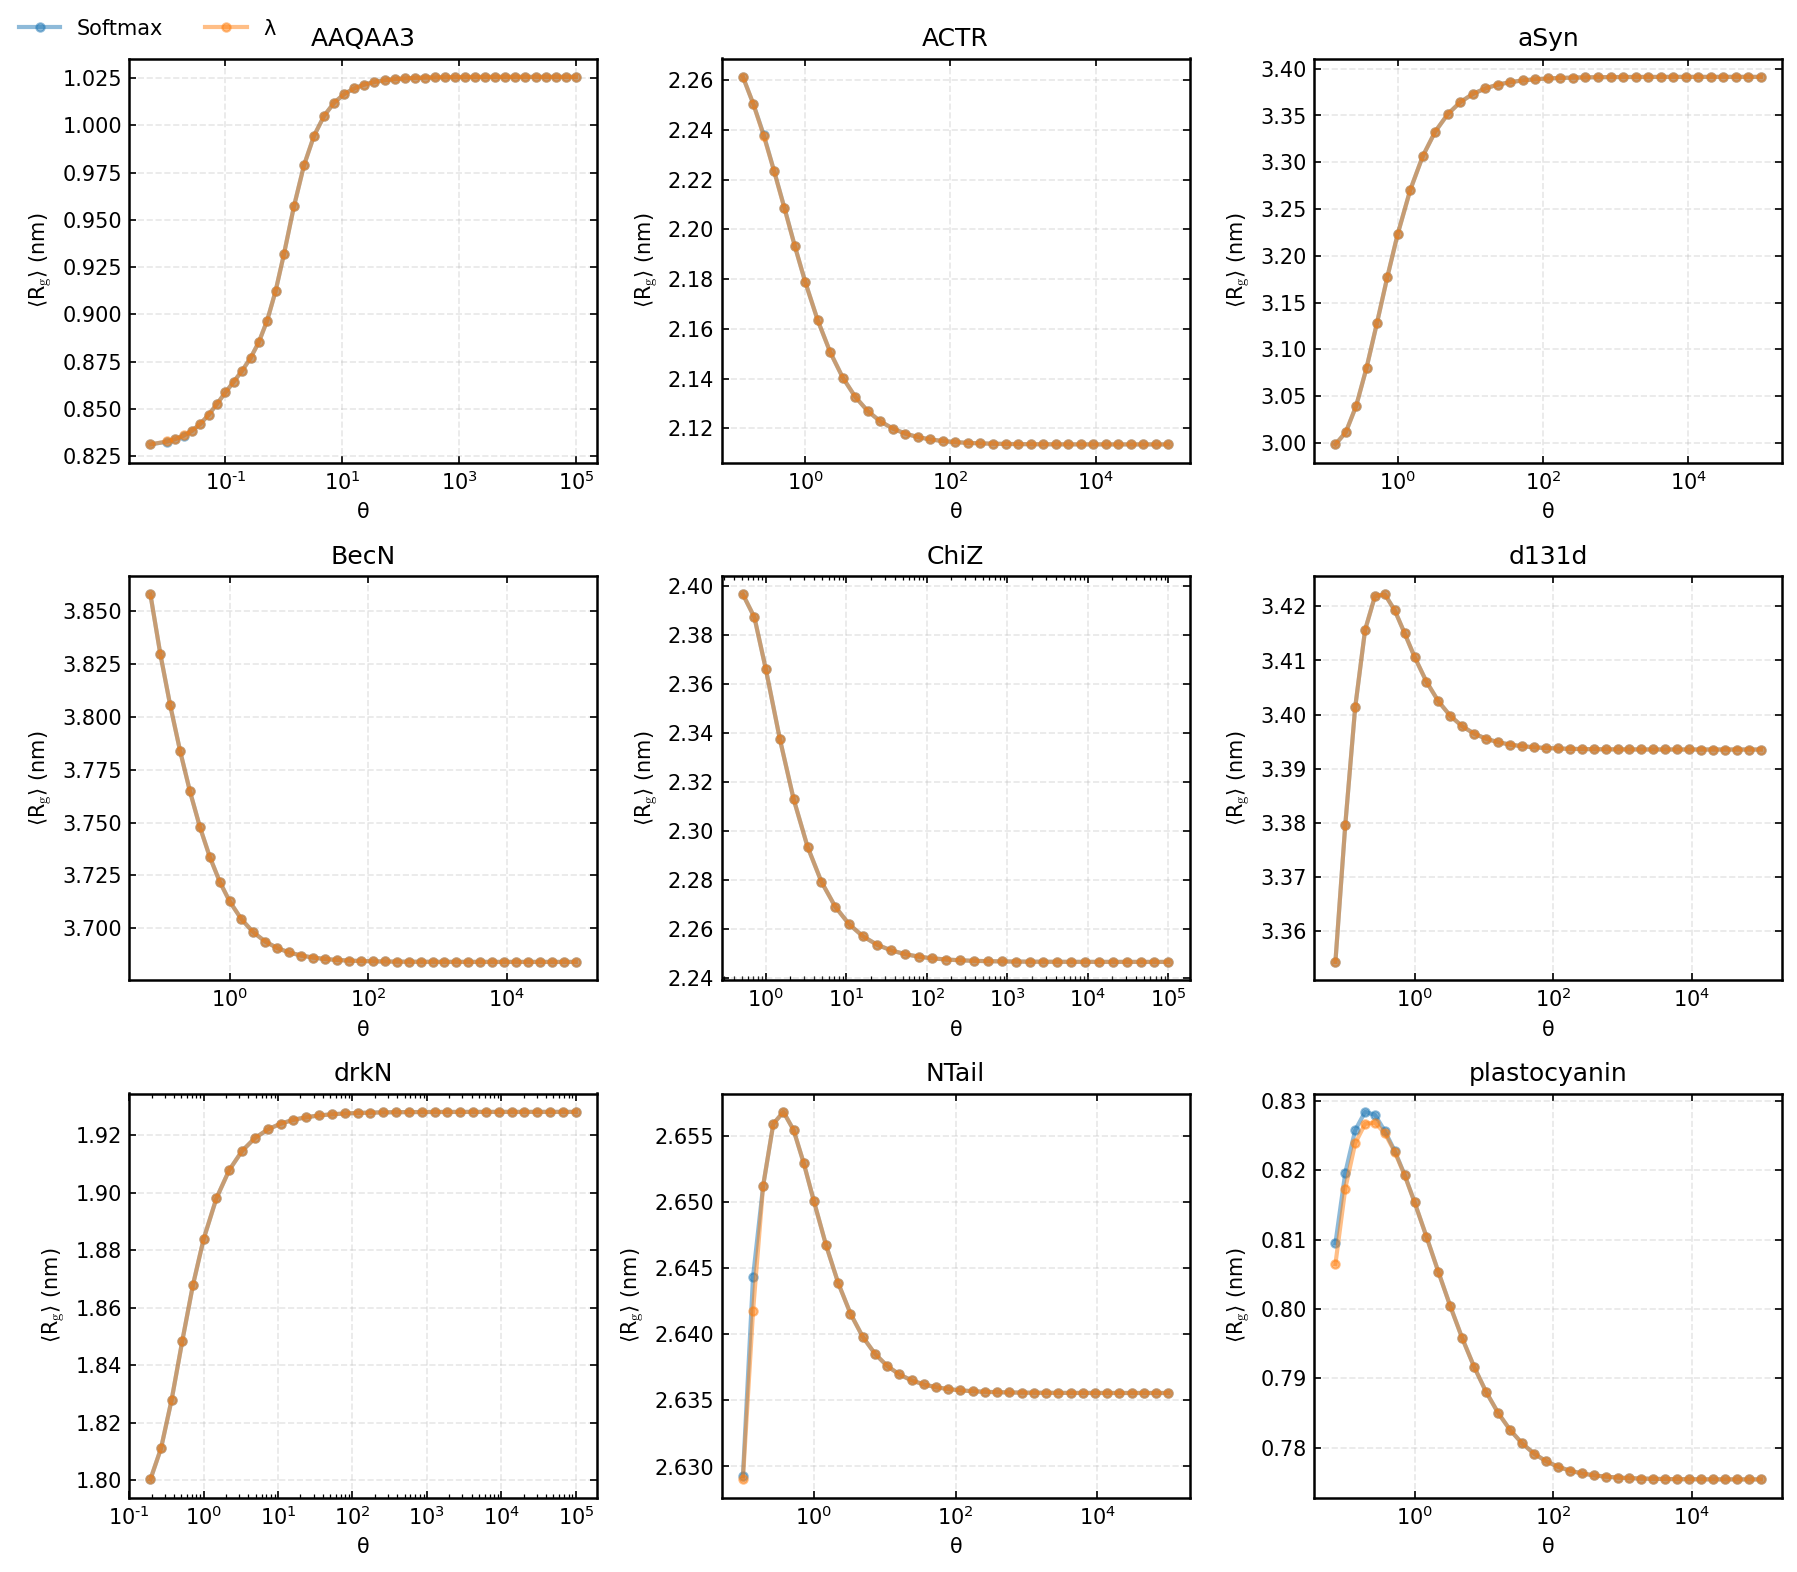

In [59]:
# rg as a function of phi during reweighting for softmax and log_lambda
model = 'rewM12DH_scaled'
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail', 'plastocyanin']

ncols = 3
nrows = math.ceil(len(proteins) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.5 * nrows))
axes = np.asarray(axes).ravel()

for ax, protein in zip(axes, proteins):
    path = f'../../MD_DATA/{protein}/{model}'
    trajs = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))
    wopt_array = np.load(f'{path}/log_wopt_array.npy')
    wopt_array_lambda = np.load(f'{path}/log_lambda_wopt_array.npy')
    rew_data = np.loadtxt(f'{path}/log_reweighting_chi2_phi_theta.txt')
    rew_data_lambda = np.loadtxt(f'{path}/log_lambda_reweighting_chi2_phi_theta.txt')
    rg = np.concatenate([np.loadtxt(f'../../MD_DATA/{protein}/rg_data/rg_{traj[:-4]}.txt') for traj in trajs], axis=0)
    rg_softmax = [np.average(rg, axis=0, weights=W) for W in wopt_array]
    rg_lambda = [np.average(rg, axis=0, weights=W) for W in wopt_array_lambda]
    ax.plot(rew_data[2, :], rg_softmax, '-o', markersize=4, label='Softmax', alpha=0.5)
    ax.plot(rew_data_lambda[2, :], rg_lambda, '-o', markersize=4, label=r'$\lambda$', alpha=0.5)
    ax.set_xscale('log')
    ax.set_title(protein)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel(r'$\langle R_{\mathrm{g}}\rangle$ (nm)')
    ax.grid(alpha=0.3)

for ax in axes[len(proteins):]:
    ax.remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=2, frameon=False)
fig.tight_layout()
plt.savefig(f'{model}_theta_rg_multipanel.png', dpi=300, bbox_inches='tight')
plt.show()

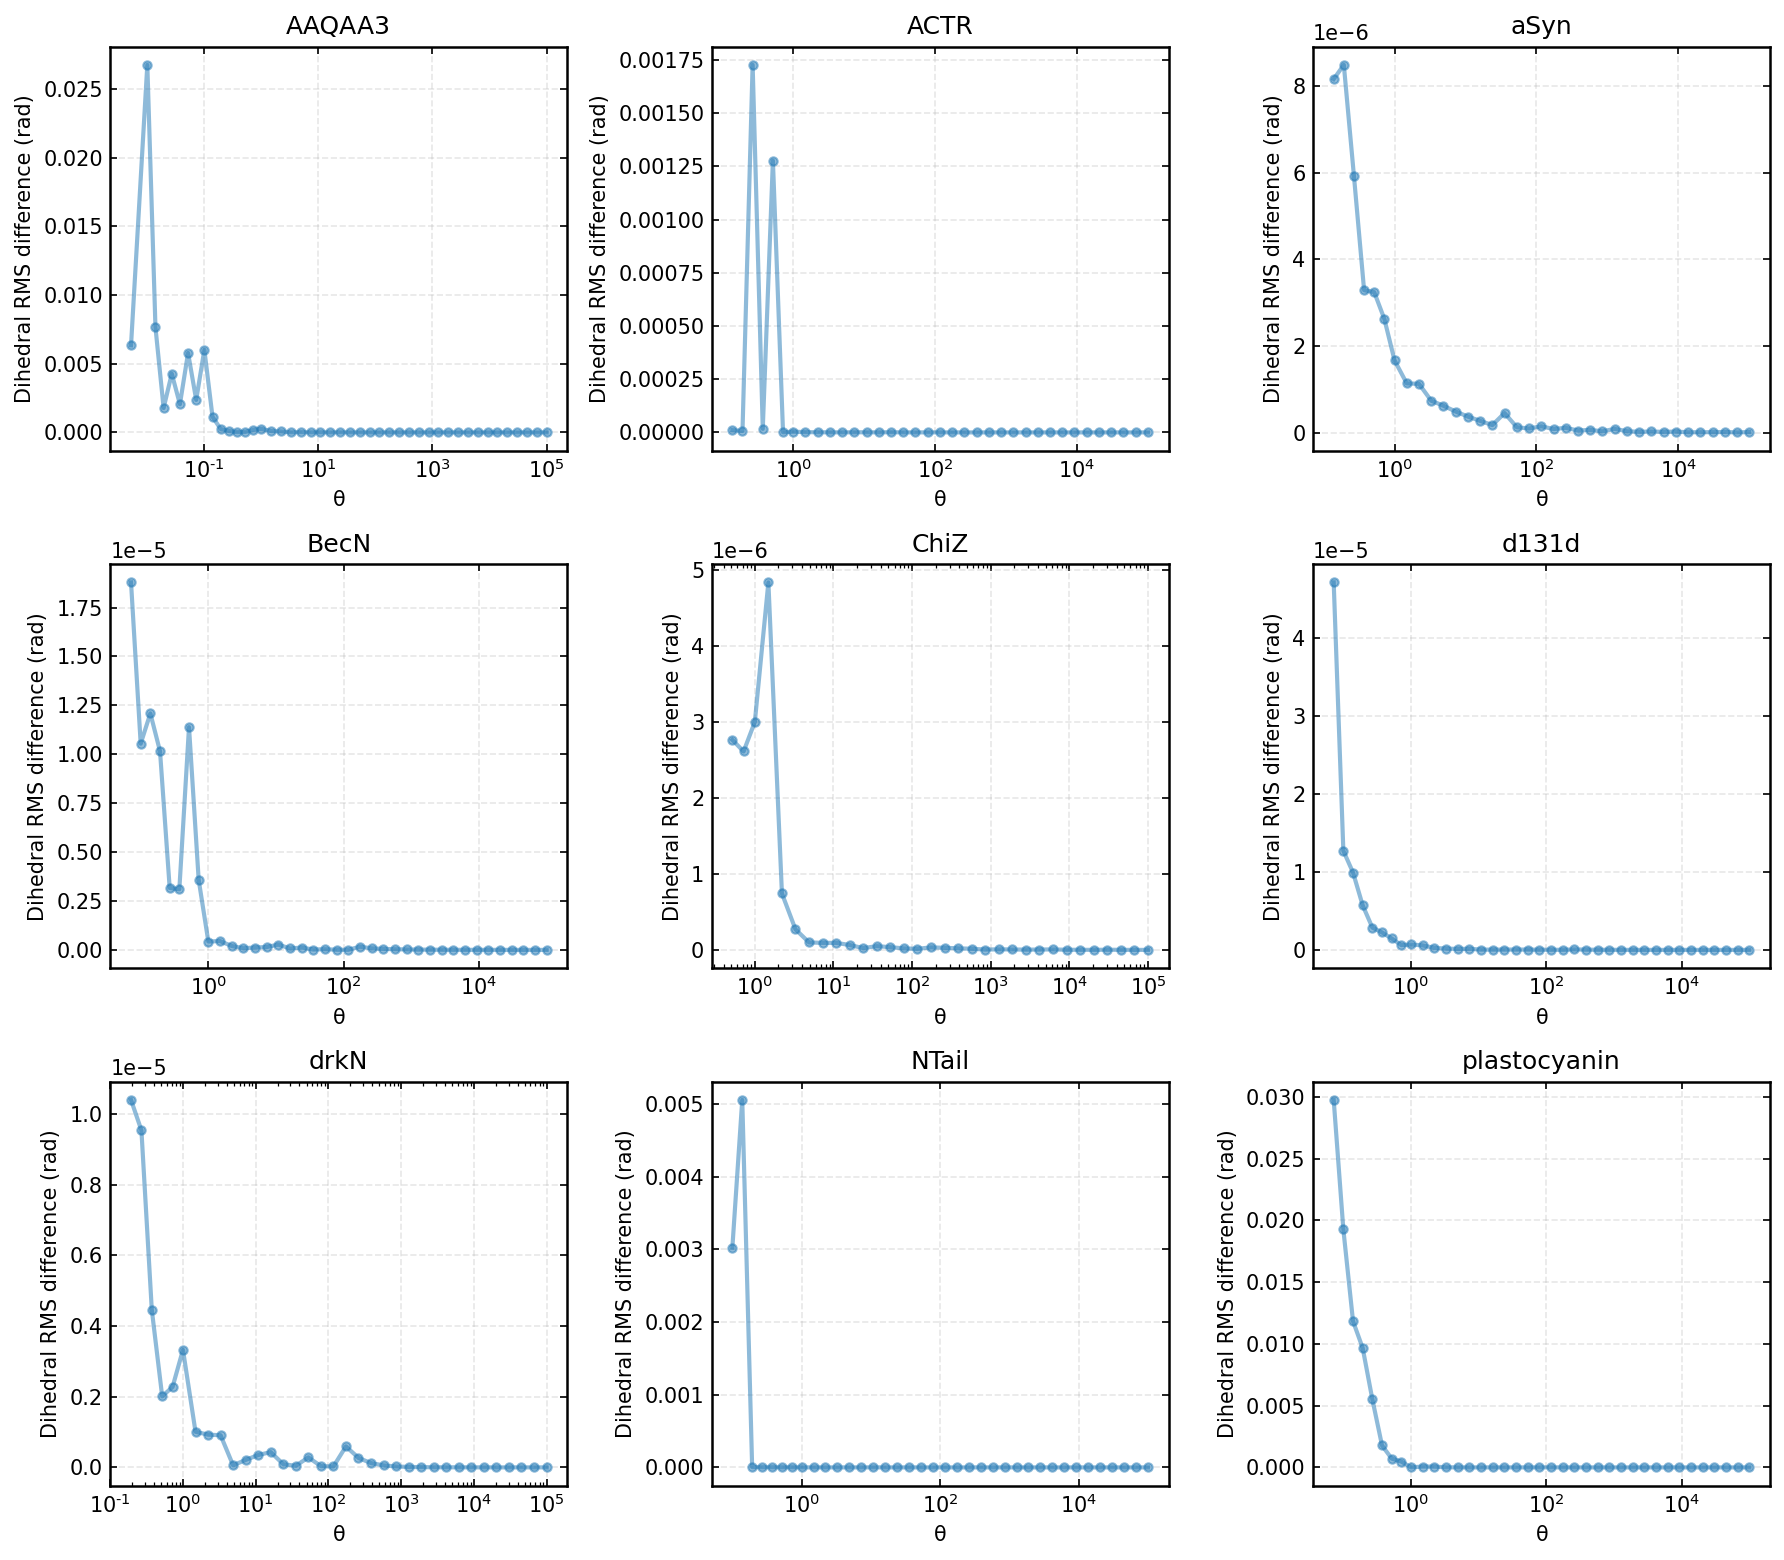

In [58]:
# RMSD between ensemble averaged phi, psi

model = 'rewM12DH_scaled'
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail', 'plastocyanin']

ncols = 3
nrows = math.ceil(len(proteins) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.5 * nrows))
axes = np.asarray(axes).ravel()

for ax, protein in zip(axes, proteins):
    path = f'../../MD_DATA/{protein}/{model}'
    trajs = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))
    wopt_array = np.load(f'{path}/log_wopt_array.npy')
    wopt_array_lambda = np.load(f'{path}/log_lambda_wopt_array.npy')
    rew_data = np.loadtxt(f'{path}/log_reweighting_chi2_phi_theta.txt')
    rew_data_lambda = np.loadtxt(f'{path}/log_lambda_reweighting_chi2_phi_theta.txt')
    dih = np.concatenate([np.concatenate((np.load(f'../../MD_DATA/{protein}/dihedrals/phi_{traj[:-4]}.npy'), np.load(f'../../MD_DATA/{protein}/dihedrals/psi_{traj[:-4]}.npy')), axis=1) for traj in trajs], axis=0)
    avg_dih = np.array([np.arctan2(np.average(np.sin(dih), axis=0, weights=W), np.average(np.cos(dih), axis=0, weights=W)) for W in wopt_array])
    avg_dih_lambda = np.array([np.arctan2(np.average(np.sin(dih), axis=0, weights=W), np.average(np.cos(dih), axis=0, weights=W)) for W in wopt_array_lambda])
    npoints = min(len(avg_dih), len(avg_dih_lambda), rew_data.shape[1], rew_data_lambda.shape[1])
    delta = np.angle(np.exp(1j * (avg_dih[:npoints] - avg_dih_lambda[:npoints])))
    rms = np.sqrt(np.mean(delta**2, axis=1))
    ax.plot(rew_data[2, :npoints], rms, '-o', markersize=4, alpha=0.5)
    ax.set_xscale('log')
    ax.set_title(protein)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel('Dihedral RMS difference (rad)')
    ax.grid(alpha=0.3)

for ax in axes[len(proteins):]:
    ax.remove()

fig.tight_layout()
plt.savefig(f'{model}_theta_dihedral_rms_multipanel.png', dpi=300, bbox_inches='tight')
plt.show()

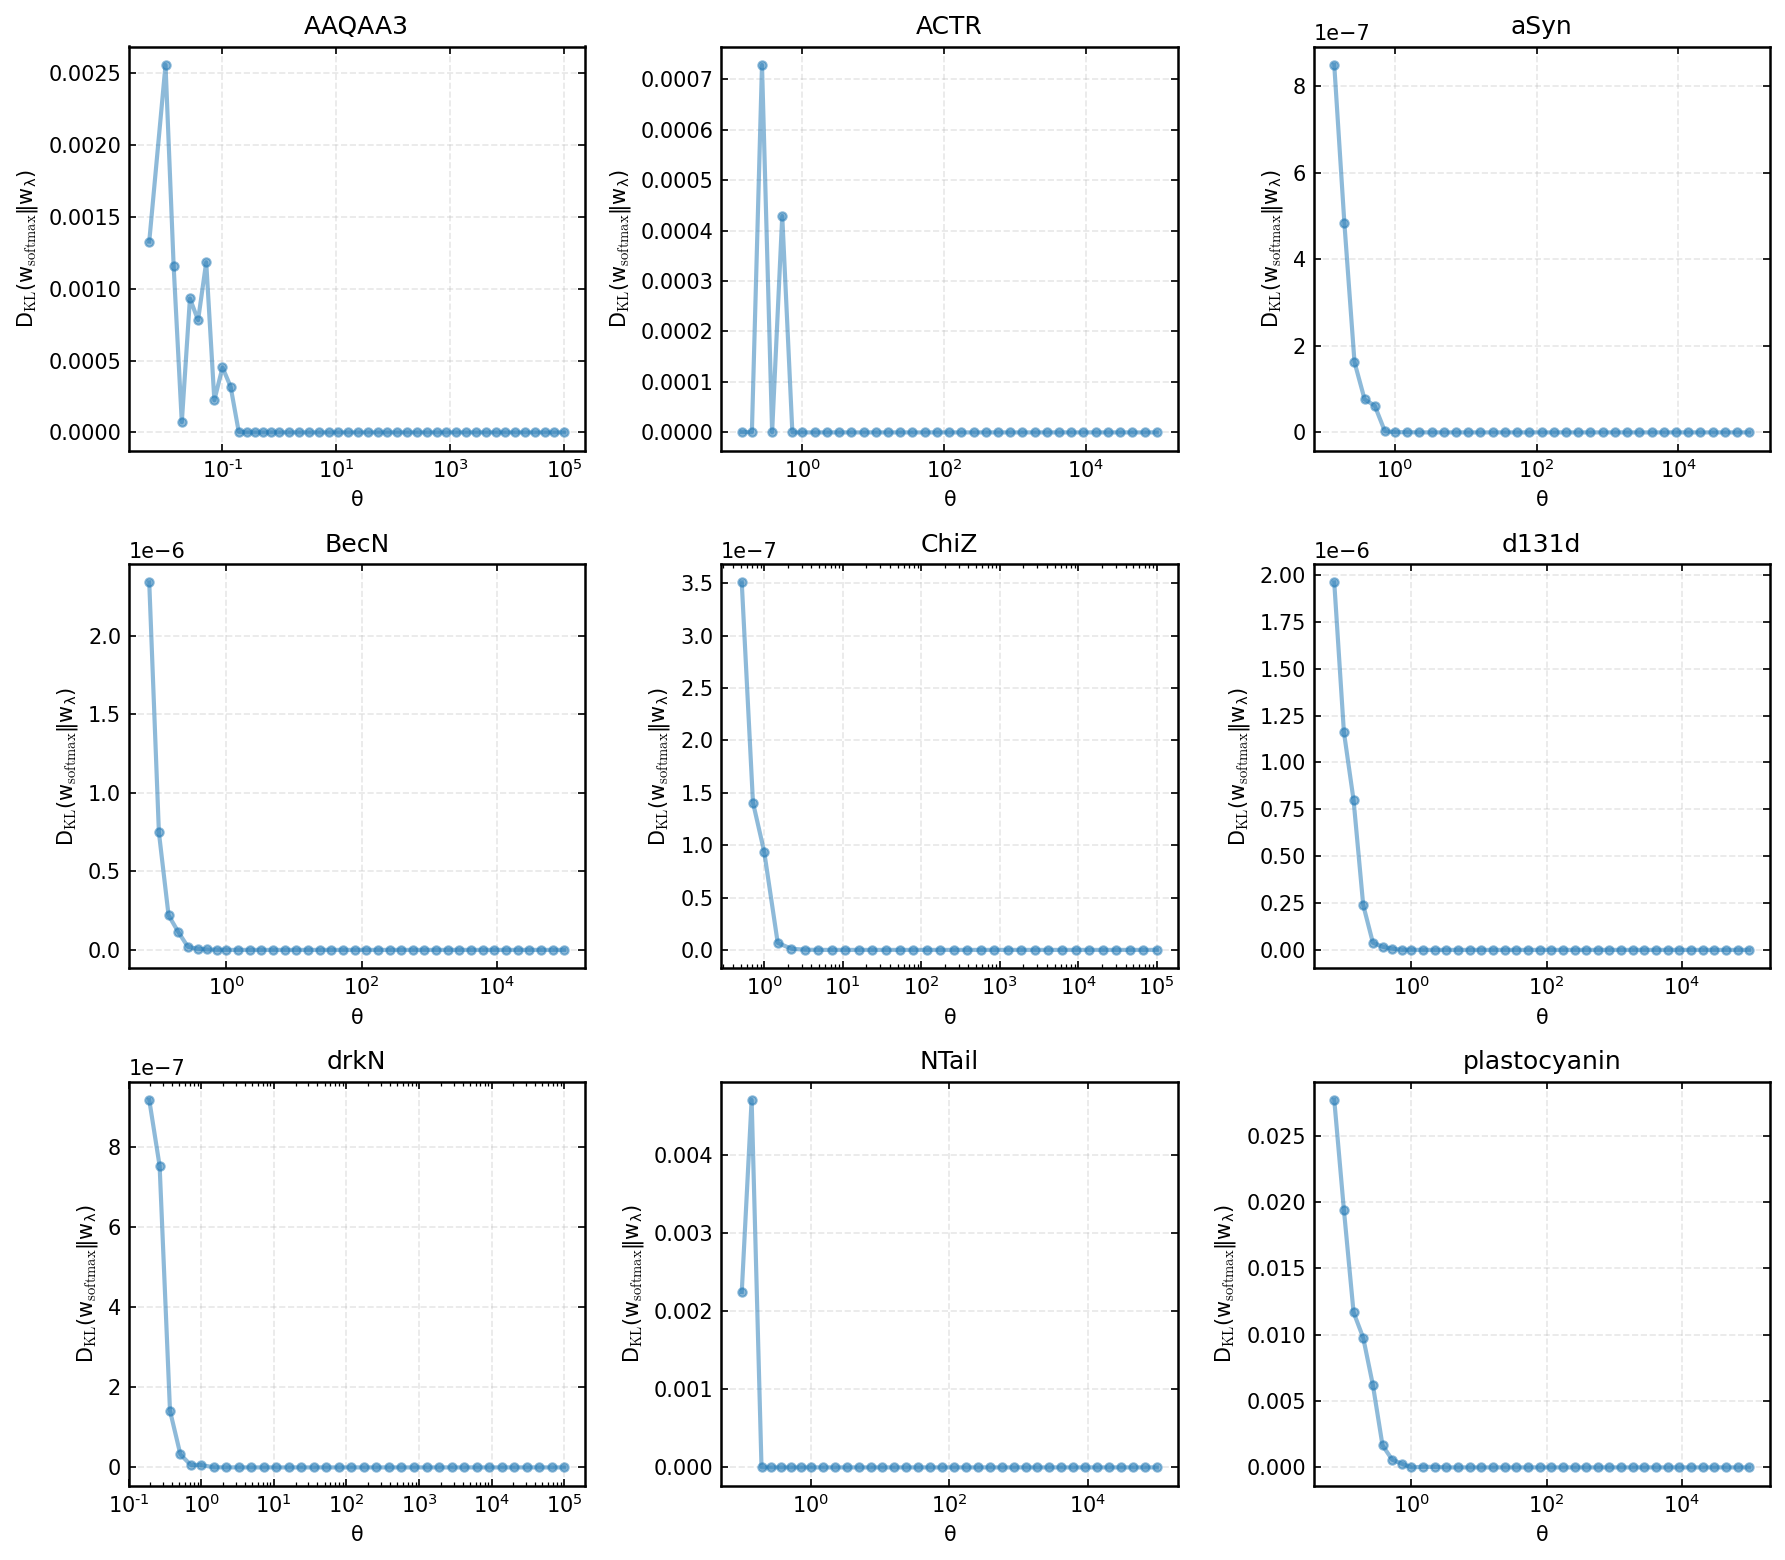

In [60]:
# KL divergence between wopt for each theta (expect some difference towards lower theta)

model = 'rewM12DH_scaled'
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail', 'plastocyanin']

ncols = 3
nrows = math.ceil(len(proteins) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.5 * nrows))
axes = np.asarray(axes).ravel()

for ax, protein in zip(axes, proteins):
    path = f'../../MD_DATA/{protein}/{model}'
    wopt_array = np.load(f'{path}/log_wopt_array.npy')
    wopt_array_lambda = np.load(f'{path}/log_lambda_wopt_array.npy')
    rew_data = np.loadtxt(f'{path}/log_reweighting_chi2_phi_theta.txt')
    npoints = min(len(wopt_array), len(wopt_array_lambda), rew_data.shape[1])
    eps = 1e-300
    kl = []
    for i in range(npoints):
        p = np.clip(wopt_array[i], eps, None)
        q = np.clip(wopt_array_lambda[i], eps, None)
        p = p / np.sum(p)
        q = q / np.sum(q)
        kl.append(np.sum(p * np.log(p / q)))
    ax.plot(rew_data[2, :npoints], kl, '-o', markersize=4, alpha=0.5)
    ax.set_xscale('log')
    ax.set_title(protein)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel(r'$D_{\mathrm{KL}}(w_{\mathrm{softmax}}\Vert w_{\lambda})$')
    ax.grid(alpha=0.3)

for ax in axes[len(proteins):]:
    ax.remove()

fig.tight_layout()
plt.savefig(f'{model}_theta_weight_KL_multipanel.png', dpi=300, bbox_inches='tight')
plt.show()